In [1]:
import matplotlib.pyplot as plt

In [2]:
image = plt.imread("Photo.jpg")

In [3]:
print(image.shape)

(3508, 2552, 3)


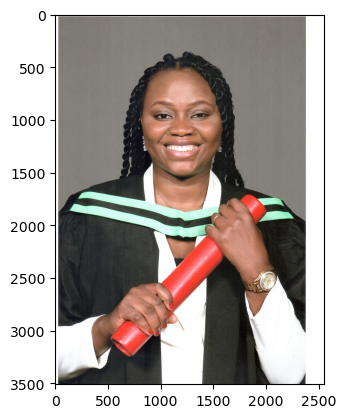

In [4]:
plt.imshow(image)
plt.show()

In [5]:
print(image)

[[[255 255 255]
  [255 255 255]
  [255 255 255]
  ...
  [255 255 255]
  [255 255 255]
  [255 255 255]]

 [[255 255 255]
  [255 255 255]
  [255 255 255]
  ...
  [255 255 255]
  [255 255 255]
  [255 255 255]]

 [[255 255 255]
  [255 255 255]
  [255 255 255]
  ...
  [255 255 255]
  [255 255 255]
  [255 255 255]]

 ...

 [[255 255 255]
  [255 255 255]
  [255 255 255]
  ...
  [253 253 253]
  [252 252 252]
  [252 252 252]]

 [[255 255 255]
  [255 255 255]
  [255 255 255]
  ...
  [253 253 253]
  [252 252 252]
  [252 252 252]]

 [[255 255 255]
  [255 255 255]
  [255 255 255]
  ...
  [253 253 253]
  [252 252 252]
  [251 251 251]]]


In [6]:
import numpy as np
image_array = np.array(image)

In [7]:
#Reading images using tensorflow
from tensorflow.keras.utils import load_img

In [8]:
image_tensor = load_img("Photo.jpg")

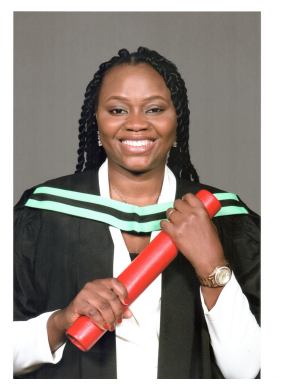

In [9]:
plt.imshow(image_tensor)
plt.axis("off")
plt.show()

In [10]:
print(type(image_tensor))

<class 'PIL.JpegImagePlugin.JpegImageFile'>


In [11]:
imageArray1 = np.array(image_tensor)
print(imageArray1)

[[[255 255 255]
  [255 255 255]
  [255 255 255]
  ...
  [255 255 255]
  [255 255 255]
  [255 255 255]]

 [[255 255 255]
  [255 255 255]
  [255 255 255]
  ...
  [255 255 255]
  [255 255 255]
  [255 255 255]]

 [[255 255 255]
  [255 255 255]
  [255 255 255]
  ...
  [255 255 255]
  [255 255 255]
  [255 255 255]]

 ...

 [[255 255 255]
  [255 255 255]
  [255 255 255]
  ...
  [253 253 253]
  [252 252 252]
  [252 252 252]]

 [[255 255 255]
  [255 255 255]
  [255 255 255]
  ...
  [253 253 253]
  [252 252 252]
  [252 252 252]]

 [[255 255 255]
  [255 255 255]
  [255 255 255]
  ...
  [253 253 253]
  [252 252 252]
  [251 251 251]]]


In [12]:
from tensorflow.keras.utils import img_to_array
imageArray2 = img_to_array(image_tensor)

In [13]:
#image = load_img("Photo.jpg", target_size = (244, 244))

In [14]:
from skimage.transform import resize

In [15]:
image_size = (244, 244)
new_image = resize(imageArray2, image_size)

In [16]:
print(new_image.shape)

(244, 244, 3)


Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers). Got range [0.0..255.0].


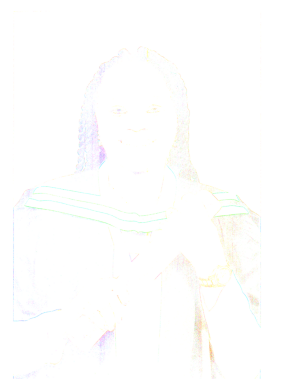

In [17]:
plt.imshow(imageArray2)
plt.axis("off")
plt.show()

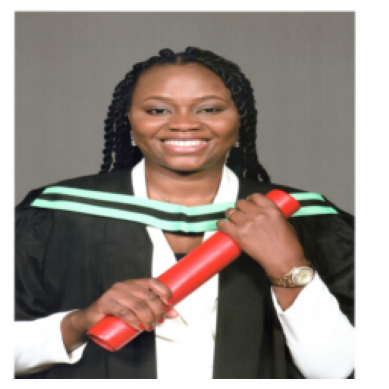

In [18]:
new_image = new_image / 255.0
plt.imshow(new_image)
plt.axis("off")
plt.show()

In [19]:
new_image = np.expand_dims(new_image, axis = 0)
print(new_image.shape)

(1, 244, 244, 3)


In [20]:
from tensorflow.keras.utils import image_dataset_from_directory

In [21]:
images = image_dataset_from_directory("dataset", image_size = (224, 224), batch_size = 32)

Found 12 files belonging to 2 classes.


In [22]:
print(images.class_names)

['Cats', 'Dogs']


In [23]:
#Get the shape of the images
for image, label in images.take(1):
    print(image.shape)
    print(label.shape)
    print(image.dtype)
    print(label.dtype)

(12, 224, 224, 3)
(12,)
<dtype: 'float32'>
<dtype: 'int32'>


In [24]:
#Access individual image
for image, label in images.take(1):
    print(image[0].shape)
    print(image[0].dtype)

(224, 224, 3)
<dtype: 'float32'>


In [25]:
#Count the total number of images
No_of_batches = len(images)
batch_size = 12
total_images = No_of_batches * batch_size

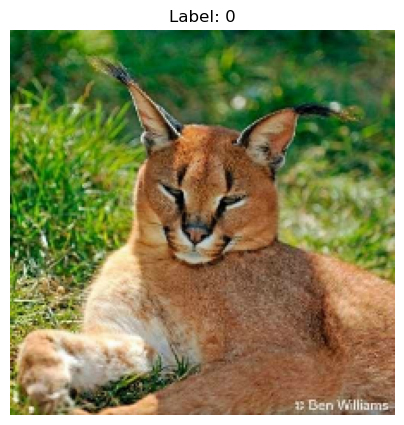

In [26]:
#Display one of the images
for image, label in images.take(1):
    image_1 = image[0]
    label_1 = label[0]

    plt.figure(figsize = (5, 5))

    if image_1.numpy().max() > 1.0:
        plt.imshow(image_1/255.0)
    else:
        plt.imshow(image_1)

    plt.title(f"Label: {label_1}")
    plt.axis("off")
    plt.show()

In [27]:
#Display all the images with class names
def show_with_class_names(dataset):
    class_names = images.class_names

    for image, label in images.take(1):

        fig, axes = plt.subplots(3, 3, figsize = (10, 10))
        axes = axes.flatten()

        for i in range(9):
            img = image[i]
            label_id = int(label[i].numpy())
            label_name = class_names[label_id]

            if img.numpy().max() > 1.0:
                img = img/255.0

            #Display the image
            axes[i].imshow(img)
            axes[i].set_title(
                f"Class: {label_name}\n"
                f"(ID: {label_id})\n"
                f"(Min: {img.numpy().min():.3f} Max: {img.numpy().max():.3f})"
            )
            axes[i].axis("off")

        plt.tight_layout()
        plt.show()
        break

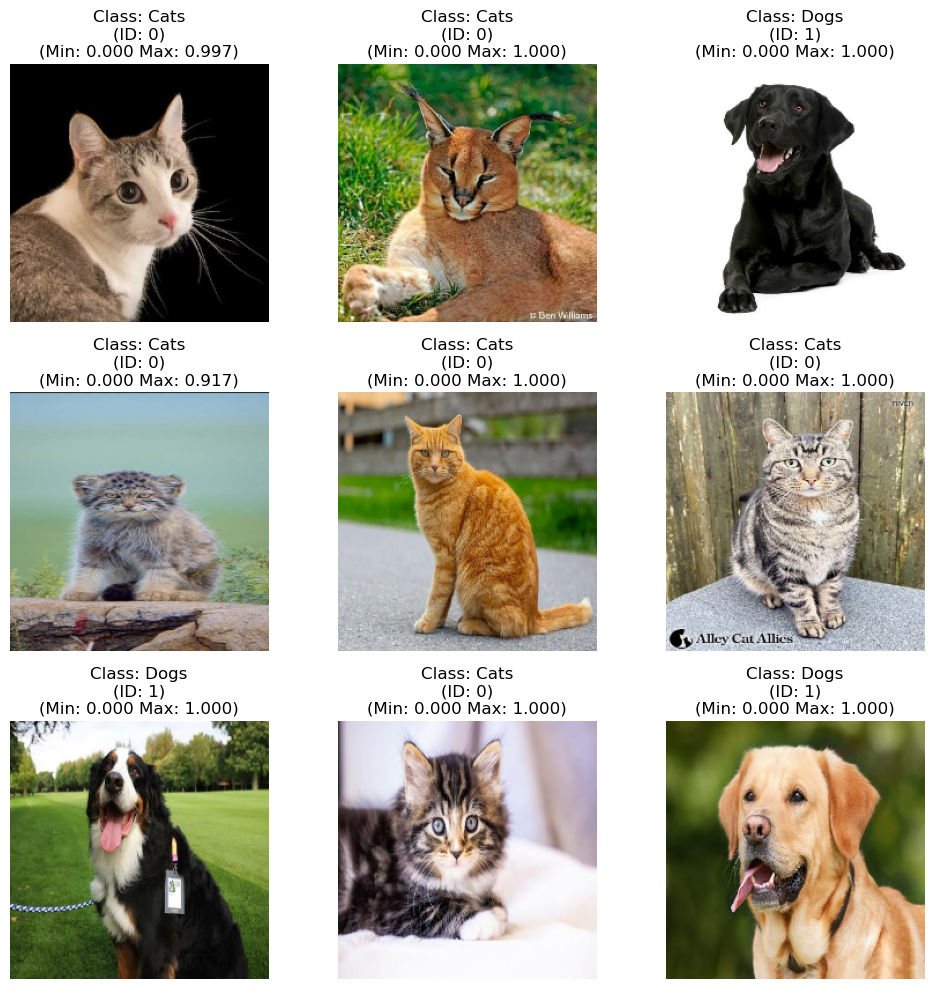

In [28]:
show_with_class_names(images)

#### Common Problems and Solutions

##### Too bright or faint image

Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers). Got range [0.0..255.0].


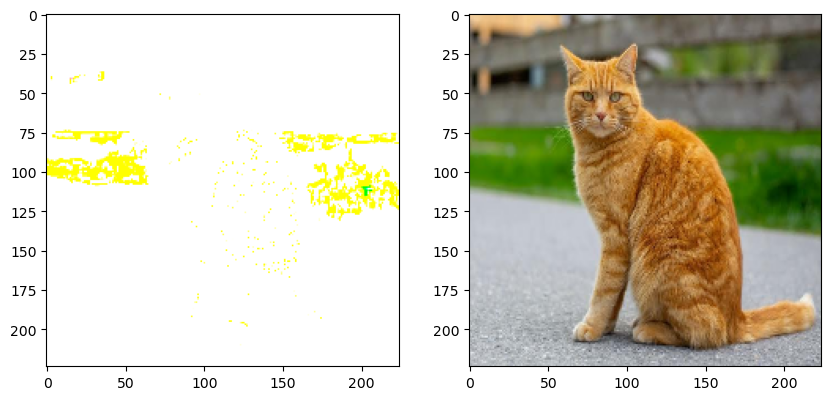

In [29]:
for image, label in images.take(1):

    img = image[0]

    fig, axes = plt.subplots(1, 2, figsize=(10, 10))
    axes = axes.flatten()

    axes[0].imshow(img) #washed up image

    axes[1].imshow(img / 255.0)

##### Negative values

Min: 0.0, Max: 255.0


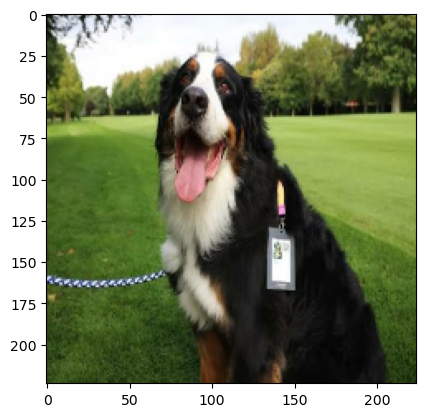

In [30]:
for image, label in images.take(1):
    img = image[0]
    print(f"Min: {img.numpy().min()}, Max: {img.numpy().max()}") #[negative values]

    img_normalize = (img - img.numpy().min()) / (img.numpy().max() - img.numpy().min())
    plt.imshow(img_normalize)


#### Convert Entire Image Dataset to Array

In [31]:
all_images = []
all_labels = []

for image_batch, label_batch in images:
    all_images.append(image_batch.numpy())
    all_labels.append(label_batch.numpy())

imagesArray = np.concatenate(all_images, axis = 0)
labelsArray = np.concatenate(all_labels, axis = 0)

In [32]:
print(imagesArray.shape)
print(labelsArray.shape)

(12, 224, 224, 3)
(12,)


In [33]:
print(labelsArray[0])
print(imagesArray[0])

0
[[[  0.         0.         0.      ]
  [  0.         0.         0.      ]
  [  0.         0.         0.      ]
  ...
  [  0.         0.         0.      ]
  [  0.         0.         0.      ]
  [  0.         0.         0.      ]]

 [[  0.         0.         0.      ]
  [  0.         0.         0.      ]
  [  0.         0.         0.      ]
  ...
  [  0.         0.         0.      ]
  [  0.         0.         0.      ]
  [  0.         0.         0.      ]]

 [[  0.         0.         0.      ]
  [  0.         0.         0.      ]
  [  0.         0.         0.      ]
  ...
  [  0.         0.         0.      ]
  [  0.         0.         0.      ]
  [  0.         0.         0.      ]]

 ...

 [[ 96.559326  78.703125  64.41553 ]
  [102.20923   84.26221   70.15625 ]
  [107.1875    89.437256  74.937744]
  ...
  [  0.         0.         0.      ]
  [  0.         0.         0.      ]
  [  0.         0.         0.      ]]

 [[ 93.25488   75.25488   61.254883]
  [103.78491   85.78491   71.78491 

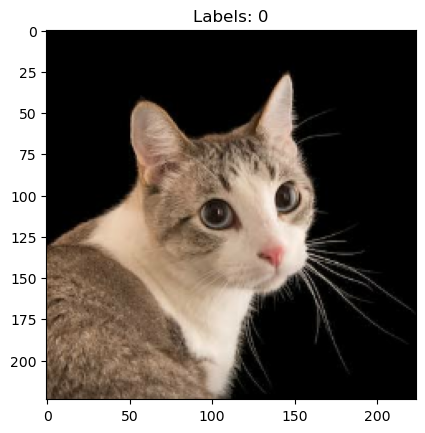

In [34]:
plt.imshow(imagesArray[0] / 255.0)
plt.title(f"Labels: {labelsArray[0]}")
plt.show()

#### Export all images from the numpy array as files

In [35]:
import os

#Create an output folder
output_folder = "exported_image_test"
os.makedirs(output_folder, exist_ok = True)

for i, image in enumerate(imagesArray):

    image = image.astype("uint8")

    filename = os.path.join(output_folder, f"image_{i}.jpg")

    plt.imsave(filename, image)

print(f"{len(imagesArray)} images exported successfully")

12 images exported successfully


#### Export Images with Label

In [37]:
class_names = images.class_names

folder_name = "exported_images_withlabels"

os.makedirs(folder_name, exist_ok = True)

for i, image in enumerate(imagesArray):

    label = labelsArray[i] #Get label number for this image

    class_name = class_names[label] # Convert label to class name

    class_folder = os.path.join(folder_name, class_name) # Create the path

    os.makedirs(class_folder, exist_ok = True) #Physically create the folder

    image = image.astype("uint8") # convert image to uint8

    filename = os.path.join(class_folder, f"image_{i}.jpg") #save image
    plt.imsave(filename, image)

print("Images exported")

Images exported


In [39]:
import tensorflow as tf

folder_name = "exported_images_withlabels"

images = tf.keras.utils.image_dataset_from_directory(
    folder_name,
    image_size = (224, 224),
    batch_size = 32, 
    shuffle = True
)

Found 12 files belonging to 2 classes.


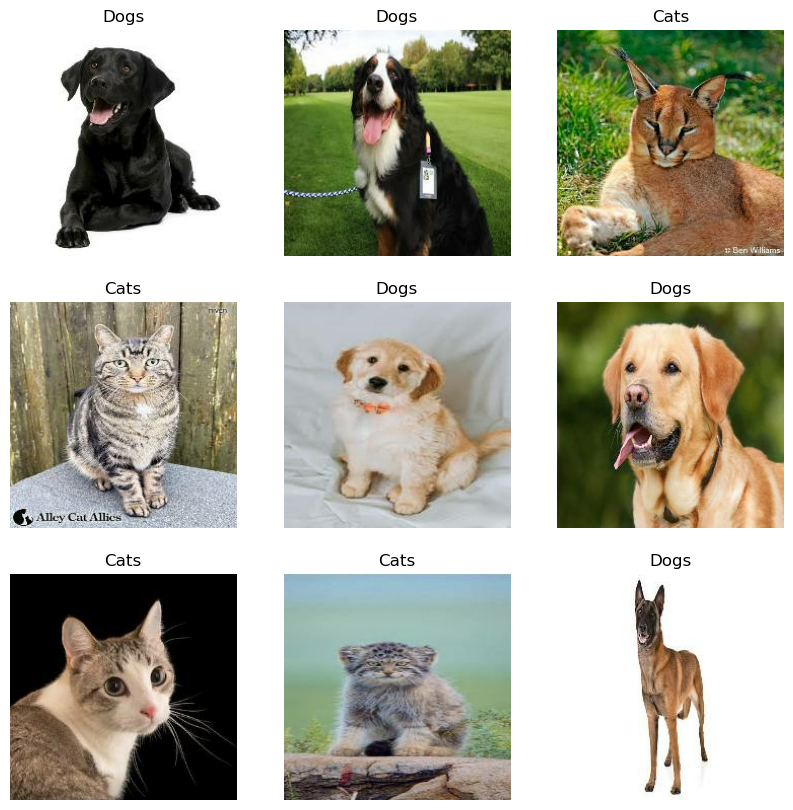

In [40]:
import matplotlib.pyplot as plt

plt.figure(figsize = (10, 10))

for image_batch, label_batch in images.take(1):
    for i in range(9):
        plt.subplot(3, 3, i + 1)
        plt.imshow(image_batch[i].numpy().astype("uint8"))
        plt.title(class_names[label_batch[i]])
        plt.axis("off")
plt.show()

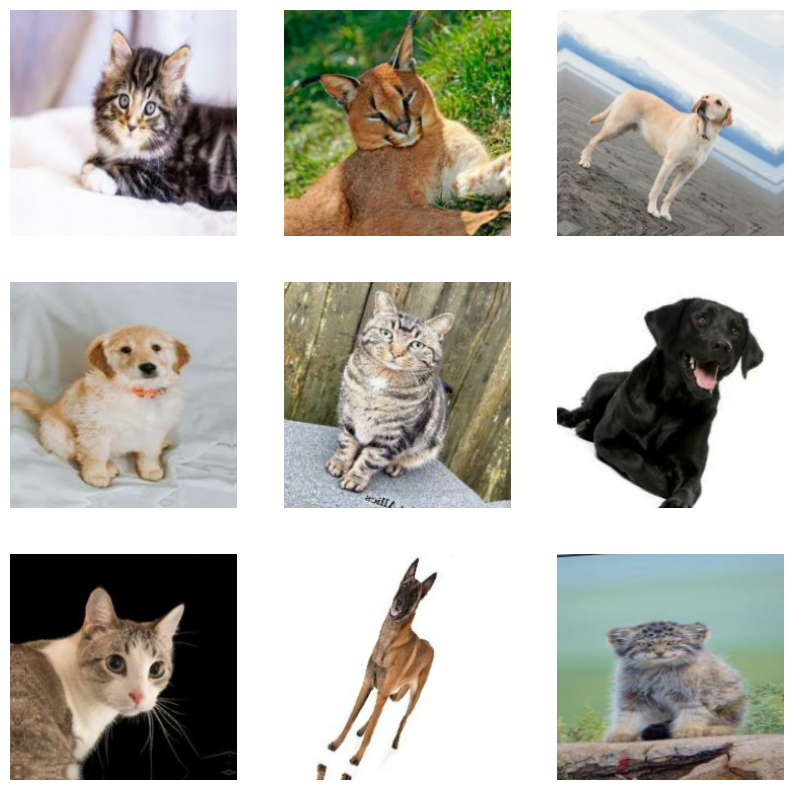

In [42]:
#Image augmentation

data_augmentation = tf.keras.Sequential([
    tf.keras.layers.RandomFlip("horizontal"),
    tf.keras.layers.RandomRotation(0.1),
    tf.keras.layers.RandomZoom(0.1)
])

for image, label in images.take(1):
    plt.figure(figsize = (10, 10))

    for i in range(9):

        augmented_image = data_augmentation(
            image[i:i+1],
            training = True
        )

        plt.subplot(3, 3, i+1)
        plt.imshow(
            augmented_image[0].numpy().astype("uint8")
        )
        plt.axis("off")
    plt.show()

In [45]:
num_augmentations = 4

image_number = 0

class_names = images.class_names

output_directory = "augmented_dataset"
os.makedirs(output_directory, exist_ok = True)

for image, label in images:

    for i in range(len(image)):

        image_1 = image[i]

        label_1 = label[i].numpy()

        class_name = class_names[label_1]

        class_folder = os.path.join(output_directory, class_name)
        os.makedirs(class_folder, exist_ok = True)

        #Save the original image file
        original_image = image_1.numpy().astype("uint8")
        original_filename = os.path.join(class_folder, f"image_{image_number}.jpg")

        plt.imsave(original_filename, original_image)

        for j in range(num_augmentations):

            image_batch = tf.expand_dims(image_1, axis = 0) #Add batch dimension
            augmented_image = data_augmentation(image_batch, training=True)

            augmented_image = augmented_image[0]
            augmented_image = augmented_image.numpy()

            #Ensure valid pixel values
            augmented_image = (
                augmented_image.clip(0, 255).astype("uint8")
            )

            #Create filename
            augmented_filename = os.path.join(
                class_folder, f"image_{image_number}_aug_{j+1}.jpg"
            )

            #Save augmented image
            plt.imsave(augmented_filename, augmented_image)

            image_number +=1
            
print("Augmentation Completed")       

Augmentation Completed


### Using a larger dataset

In [46]:
folder_name = "PetImages"

petImages = tf.keras.utils.image_dataset_from_directory(
    folder_name,
    image_size = (180, 180),
    batch_size = 32,
    shuffle = True,
    seed = 42
)

Found 24998 files belonging to 2 classes.


In [47]:
pet_class_name = petImages.class_names
print(pet_class_name)

['Cat', 'Dog']


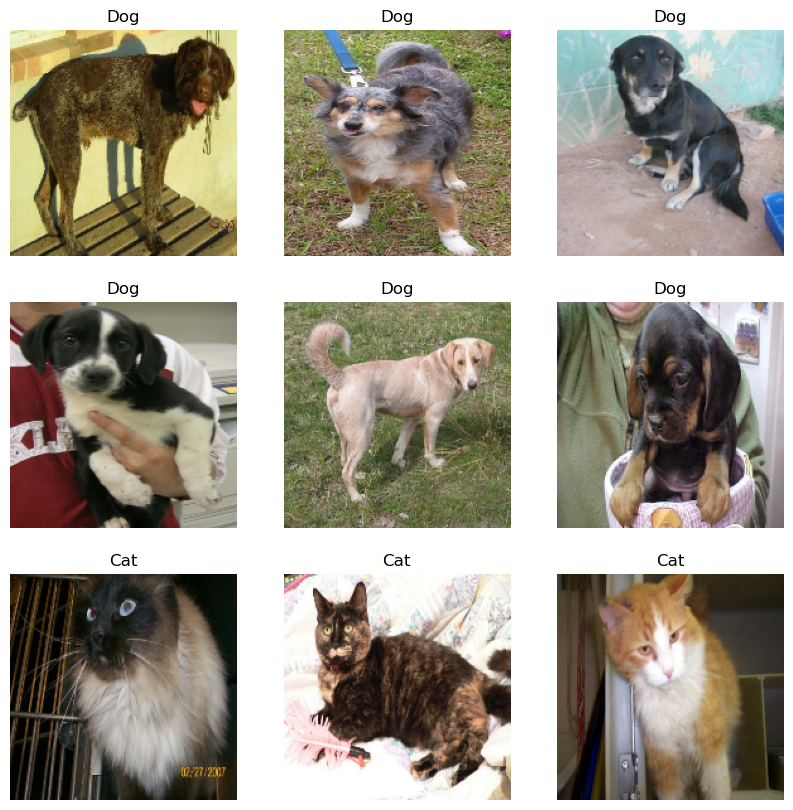

In [49]:
 plt.figure(figsize = (10, 10))

for image_batch, label_batch in petImages.take(1):
    for i in range(9):

        plt.subplot(3, 3, i+1)
        plt.imshow(image_batch[i].numpy().astype("uint8"))
        plt.title(pet_class_name[label_batch[i]])
        plt.axis("off")
plt.show()

In [50]:
#Split dataset - take() and skip()

dataset_size = tf.data.experimental.cardinality(petImages).numpy()

train_size = int(0.8 * dataset_size)
val_size = int(0.1 * dataset_size)

train_ds = petImages.take(train_size)
remaining_ds = petImages.skip(train_size)
# validation and test come from what is left after the training batches, so they don't overlap with training
val_ds = remaining_ds.take(val_size)
test_ds = remaining_ds.skip(val_size)

# PetImages contains a few corrupt files that TensorFlow can't decode; skip those batches instead of crashing
train_ds = train_ds.ignore_errors()
val_ds = val_ds.ignore_errors()
test_ds = test_ds.ignore_errors()


In [51]:
data_augmentation = tf.keras.Sequential([
    tf.keras.layers.RandomFlip("Horizontal"),
    tf.keras.layers.RandomRotation(0.2),
    tf.keras.layers.RandomZoom(0.3)
])

In [52]:
normalization = tf.keras.layers.Rescaling(1./255)

In [53]:
tf.keras.Sequential
tf.keras.layers.Rescaling
tf.keras.layers.Conv2D
tf.keras.layers.MaxPooling2D
tf.keras.layers.Flatten
tf.keras.layers.Dense

keras.src.layers.core.dense.Dense

In [56]:
model = tf.keras.Sequential([
    data_augmentation,

    tf.keras.layers.Rescaling(1./255),

    tf.keras.layers.Conv2D(32, (3, 3), activation="relu"),
    tf.keras.layers.MaxPooling2D(),

    tf.keras.layers.Conv2D(64, (3, 3), activation="relu"),
    tf.keras.layers.MaxPooling2D(),

    tf.keras.layers.Conv2D(128, (3, 3), activation="relu"),
    tf.keras.layers.MaxPooling2D(),

    # Flatten turns the 2D feature maps into one long vector so the Dense layers can use them
    tf.keras.layers.Flatten(),

    tf.keras.layers.Dense(128, activation="relu"),

    tf.keras.layers.Dense(1, activation="sigmoid")
])

In [57]:
model.compile(
    optimizer="adam",
    loss="binary_crossentropy",
    metrics=["accuracy"]
)

In [58]:
history = model.fit(
    train_ds,
    validation_data = val_ds,
    epochs = 10
)

Epoch 1/10


ValueError: Arguments `target` and `output` must have the same rank (ndim). Received: target.shape=(None,), output.shape=(None, 20, 20, 1)